# Phân tích giải đấu pilot Round-Robin — Connect Four 7×6

Dùng log `games_*.csv` theo `run_id` và ma trận tổng hợp do CLI tạo. Đây là pilot 3 tác tử, 20 ván mỗi cặp.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

summary_files = sorted(Path('../results/tables').glob('tournament-default-*_summary.csv'))
assert summary_files, 'Chua co file summary'
summary = pd.read_csv(summary_files[-1])
summary

,agent_a,agent_b,wins_a,draws,wins_b,score_a
0,random,heuristic,0,0,20,0.0
1,random,dqn,6,0,14,0.3
2,heuristic,dqn,20,0,0,1.0


In [2]:
rows = []
for _, item in summary.iterrows():
    n = int(item.wins_a + item.draws + item.wins_b)
    rows.append({
        'pair': f'{item.agent_a} vs {item.agent_b}',
        'games': n, 'wins_a': int(item.wins_a), 'draws': int(item.draws),
        'losses_a': int(item.wins_b), 'score_a': float(item.score_a),
    })
result_table = pd.DataFrame(rows)
result_table

,pair,games,wins_a,draws,losses_a,score_a
0,random vs heuristic,20,0,0,20,0.0
1,random vs dqn,20,6,0,14,0.3
2,heuristic vs dqn,20,20,0,0,1.0


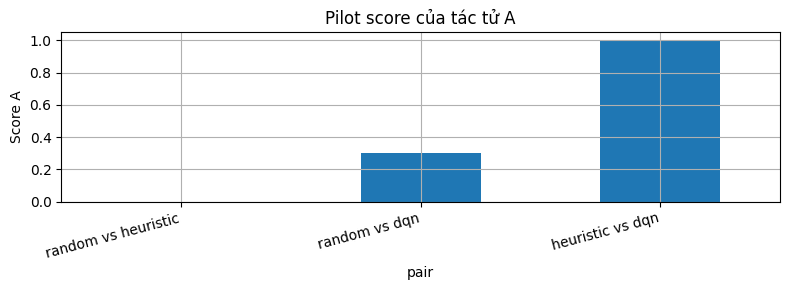

In [3]:
ax = result_table.plot(x='pair', y='score_a', kind='bar', figsize=(8, 3), legend=False, grid=True, title='Pilot score của tác tử A')
ax.set_ylim(0, 1.05); ax.set_ylabel('Score A')
plt.xticks(rotation=15, ha='right'); plt.tight_layout(); plt.show()

## Giới hạn diễn giải

Kết quả 20 ván/cặp chỉ để kiểm tra đường ống log và khả năng tích hợp. DQN thắng Random 14/20 (70%) nhưng thua Heuristic 0/20. Không được dùng mẫu pilot này thay cho giải đấu chính thức tối thiểu 100 ván/cặp hoặc chọn siêu tham số cuối.